# Machine Learning — Practical Session 1
## Exercise 1: Exploring a Tabular Dataset and Creating Data Splits

### Objective
The objective of this exercise is to load and explore the Iris dataset, select relevant features, and split the data into training and testing sets.

The Iris dataset contains four numerical measurements of flowers and a categorical target variable representing the species.

In [3]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedShuffleSplit
from sklearn.datasets import fetch_20newsgroups
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    StandardScaler,
    MinMaxScaler,
    MaxAbsScaler,
    RobustScaler,
    normalize,
    Binarizer,
    OrdinalEncoder,
    LabelEncoder,
    OneHotEncoder,
)


## Exercise 1: Exploring a tabular dataset and creating data splits

In [4]:
# 1. Load
D = pd.read_csv("../data/Iris_Dataset.csv")

In [5]:
# 2. Inspect
D.info()                # column names, dtypes, non-null counts
print(D.describe())     # mean, std, min, quartiles, max of numeric columns
print(D.shape)          # (rows, columns)
print(D.columns)        # column names
D.head()                # first 5 rows

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB
       sepal_length  sepal_width  petal_length  petal_width
count    150.000000   150.000000    150.000000   150.000000
mean       5.843333     3.054000      3.758667     1.198667
std        0.828066     0.433594      1.764420     0.763161
min        4.300000     2.000000      1.000000     0.100000
25%        5.100000     2.800000      1.600000     0.300000
50%        5.800000     3.000000      4.350000     1.300000
75%        6.400000     3.300000      5.100000     1.800000
max        7.900000     4.400000      6.900000     2.500000
(150, 5)
Index(['s

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


In [6]:
# 3-4. Two features, first 20 rows
X2 = D[["sepal_length", "petal_width"]]
X2.head(20)

,sepal_length,petal_width
0,5.1,0.2
1,4.9,0.2
2,4.7,0.2
3,4.6,0.2
4,5.0,0.2
5,5.4,0.4
6,4.6,0.3
7,5.0,0.2
8,4.4,0.2
9,4.9,0.1


In [7]:
# 5. Copy: experiment without altering the original
D_copy = D.copy()

In [8]:
# 6-7. Features / target + stratified 80/20 split
target = D.columns[-1]                 # the species column
X = D.drop(columns=[target])           # input features
y = D[target]                          # target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Features:", list(X.columns), "| Target:", target)

Features: ['sepal_length', 'sepal_width', 'petal_length', 'petal_width'] | Target: species


In [9]:
# 8. Verify sizes and proportions
print(len(X_train), len(X_test))
print(len(X_train) / len(D), len(X_test) / len(D))
print(y_train.value_counts(normalize=True))
print(y_test.value_counts(normalize=True))

120 30
0.8 0.2
species
Iris-setosa        0.333333
Iris-virginica     0.333333
Iris-versicolor    0.333333
Name: proportion, dtype: float64
species
Iris-setosa        0.333333
Iris-virginica     0.333333
Iris-versicolor    0.333333
Name: proportion, dtype: float64


## Exercise 2: Exploring text data

In [10]:
with open("../data/txt_file.txt", "r", encoding="utf-8") as f:
    for line in f:
        print(line.rstrip("\n"))

0.50,0.20,0.84,0.01,c1
0.10,0.10,0.40,0.02,c2
0.15,0.10,0.45,0.03,c2
0.22,0.20,0.90,0.01,c1
0.25,0.20,0.87,0.01,c1
0.10,0.10,0.38,0.02,c2


In [11]:
news = fetch_20newsgroups(subset="train")
print(len(news.data), "documents")
print(len(news.target), "labels")

11314 documents
11314 labels


In [12]:
print(news.data[0])
print("Target:", news.target[0])

From: lerxst@wam.umd.edu (where's my thing)
Subject: WHAT car is this!?
Nntp-Posting-Host: rac3.wam.umd.edu
Organization: University of Maryland, College Park
Lines: 15

 I was wondering if anyone out there could enlighten me on this car I saw
the other day. It was a 2-door sports car, looked to be from the late 60s/
early 70s. It was called a Bricklin. The doors were really small. In addition,
the front bumper was separate from the rest of the body. This is 
all I know. If anyone can tellme a model name, engine specs, years
of production, where this car is made, history, or whatever info you
have on this funky looking car, please e-mail.

Thanks,
- IL
   ---- brought to you by your neighborhood Lerxst ----





Target: 7


In [13]:
print(news.target_names)
print(news.target_names[news.target[0]])

['alt.atheism', 'comp.graphics', 'comp.os.ms-windows.misc', 'comp.sys.ibm.pc.hardware', 'comp.sys.mac.hardware', 'comp.windows.x', 'misc.forsale', 'rec.autos', 'rec.motorcycles', 'rec.sport.baseball', 'rec.sport.hockey', 'sci.crypt', 'sci.electronics', 'sci.med', 'sci.space', 'soc.religion.christian', 'talk.politics.guns', 'talk.politics.mideast', 'talk.politics.misc', 'talk.religion.misc']
rec.autos


In [14]:
lengths = [len(d) for d in news.data]
print("Mean length:", np.mean(lengths), "| Max length:", np.max(lengths))

Mean length: 1949.3100583348064 | Max length: 75154


## Exercise 3: Detecting and handling missing values

In [15]:
emp = pd.read_csv("../data/employees.csv")
emp.info()
emp.head()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   First Name         933 non-null    str    
 1   Gender             855 non-null    str    
 2   Start Date         1000 non-null   str    
 3   Last Login Time    1000 non-null   str    
 4   Salary             1000 non-null   int64  
 5   Bonus %            1000 non-null   float64
 6   Senior Management  933 non-null    object 
 7   Team               957 non-null    str    
dtypes: float64(1), int64(1), object(1), str(5)
memory usage: 62.6+ KB


,First Name,Gender,Start Date,Last Login Time,Salary,Bonus %,Senior Management,Team
0,Douglas,Male,8/6/1993,12:42 PM,97308,6.945,True,Marketing
1,Thomas,Male,3/31/1996,6:53 AM,61933,4.170,True,NaN
2,Maria,Female,4/23/1993,11:17 AM,130590,11.858,False,Finance
3,Jerry,Male,3/4/2005,1:00 PM,138705,9.340,True,Finance
4,Larry,Male,1/24/1998,4:47 PM,101004,1.389,True,Client Services


In [16]:
print(emp.isna().sum())

First Name            67
Gender               145
Start Date             0
Last Login Time        0
Salary                 0
Bonus %                0
Senior Management     67
Team                  43
dtype: int64


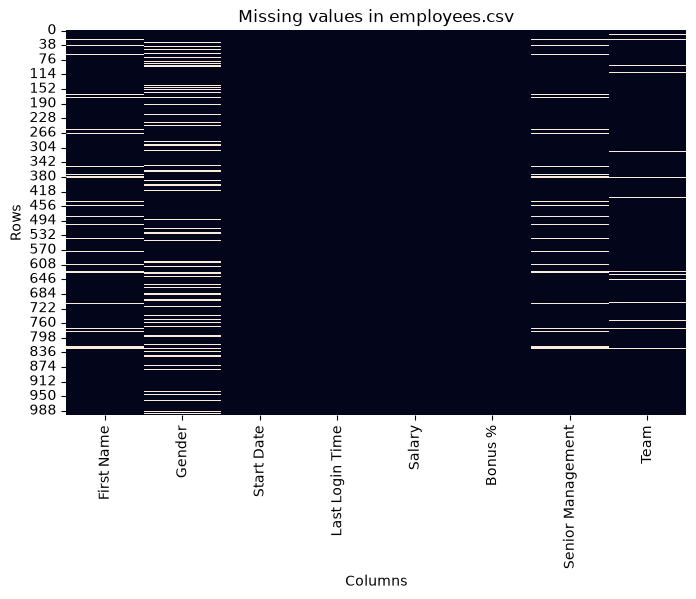

In [17]:
plt.figure(figsize=(8, 5))
sns.heatmap(emp.isna(), cbar=False)
plt.title("Missing values in employees.csv")
plt.xlabel("Columns")
plt.ylabel("Rows")
plt.show()

In [18]:
emp2 = emp.copy()
new_row = [np.nan] * len(emp2.columns)
new_row[0] = "-"
new_row[1] = "na"
emp2.loc[len(emp2)] = new_row

In [19]:
print(emp2.isna().sum())

First Name            67
Gender               145
Start Date             1
Last Login Time        1
Salary                 1
Bonus %                1
Senior Management     68
Team                  44
dtype: int64


In [20]:
emp3 = emp2.copy()
num_cols = emp3.select_dtypes(include="number").columns
cat_cols = emp3.columns.difference(num_cols)

emp3[num_cols] = SimpleImputer(strategy="median").fit_transform(emp3[num_cols])
emp3[cat_cols] = SimpleImputer(strategy="most_frequent").fit_transform(emp3[cat_cols])

In [21]:
pd.DataFrame({"before": emp2.isna().sum(), "after": emp3.isna().sum()})

,before,after
First Name,67,0
Gender,145,0
Start Date,1,0
Last Login Time,1,0
Salary,1,0
Bonus %,1,0
Senior Management,68,0
Team,44,0


In [22]:
## Exercise 4: Feature scaling, binarization and categorical encoding

In [23]:
M = np.array([[1, -1, 2],
              [2,  0, 0],
              [0,  1, -1]])

results = {
    "StandardScaler": StandardScaler().fit_transform(M),
    "MinMaxScaler":   MinMaxScaler().fit_transform(M),
    "MaxAbsScaler":   MaxAbsScaler().fit_transform(M),
    "RobustScaler":   RobustScaler().fit_transform(M),
    "normalize (L2)": normalize(M, norm="l2"),
}
for name, res in results.items():
    print(name)
    print(res.round(3))
    print()

StandardScaler
[[ 0.    -1.225  1.336]
 [ 1.225  0.    -0.267]
 [-1.225  1.225 -1.069]]

MinMaxScaler
[[0.5   0.    1.   ]
 [1.    0.5   0.333]
 [0.    1.    0.   ]]

MaxAbsScaler
[[ 0.5 -1.   1. ]
 [ 1.   0.   0. ]
 [ 0.   1.  -0.5]]

RobustScaler
[[ 0.    -1.     1.333]
 [ 1.     0.     0.   ]
 [-1.     1.    -0.667]]

normalize (L2)
[[ 0.408 -0.408  0.816]
 [ 1.     0.     0.   ]
 [ 0.     0.707 -0.707]]



In [24]:
print(Binarizer(threshold=0).fit_transform(M))

[[1 0 1]
 [1 0 0]
 [0 1 0]]


In [25]:
data = pd.DataFrame({
    "Feature 1": ["male", "female", "female", "male"],
    "Feature 2": ["from US", "from Europe", "from Asia", "from Africa"],
    "Feature 3": ["uses Safari", "uses Safari", "uses Firefox", "uses Chrome"],
    "Target":    ["US", "France", "Japan", "Algeria"],
})
X_cat = data[["Feature 1", "Feature 2", "Feature 3"]]

In [26]:
oe = OrdinalEncoder()
print(oe.fit_transform(X_cat))
print(oe.categories_)

[[1. 3. 2.]
 [0. 2. 2.]
 [0. 1. 1.]
 [1. 0. 0.]]
[array(['female', 'male'], dtype=object), array(['from Africa', 'from Asia', 'from Europe', 'from US'], dtype=object), array(['uses Chrome', 'uses Firefox', 'uses Safari'], dtype=object)]


In [27]:
le = LabelEncoder()
y_enc = le.fit_transform(data["Target"])
print(y_enc)
print(dict(zip(le.classes_, le.transform(le.classes_))))

[3 1 2 0]
{'Algeria': np.int64(0), 'France': np.int64(1), 'Japan': np.int64(2), 'US': np.int64(3)}


In [28]:
ohe = OneHotEncoder(sparse_output=False)
print(ohe.fit_transform(data[["Target"]]))
print(ohe.categories_)

[[0. 0. 0. 1.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [1. 0. 0. 0.]]
[array(['Algeria', 'France', 'Japan', 'US'], dtype=object)]
